# Single-cell NPQ scoring in the 3D (q̃E, q̃T, q̃I) space — *Chlamydomonas* (inference only)

**Paper**: "Interplay between high-energy quenching and state transitions in *Chlamydomonas reinhardtii*: a single-cell approach",
*New Phytologist* 250(4):2689–2705 (2026), DOI [10.1111/nph.71001](https://doi.org/10.1111/nph.71001) (CC BY 4.0, PMCID PMC13103431).

**Author code & data**: [DreamRepo/NPQScore-data](https://github.com/DreamRepo/NPQScore-data) @ commit
`4f0a787f327fd7d75c5a25a9d037dc937bc7e026` (authors' own repository; no LICENSE file — reuse terms unclear, paper text is CC BY 4.0).

**Scope (partial demonstration — pretrained inference, no training)**: this notebook loads the
authors' *pretrained* dictionary (`output/dico.pkl`, scikit-learn `MiniBatchDictionaryLearning`,
k=10) and their saved q̃E/q̃T/q̃I projection parameters, then scores the labelled reference traces
(~2302 single-cell Fm′ traces, 91 time points each) exactly as in the authors' `DL_LDA.ipynb`
scoring path. It **does not retrain** the dictionary/LDA and does not reproduce the microscope
acquisition. One-example caveat: population-level scores here are a plausibility check, not a
verification of the paper's dataset-level statistics.

**AI-assisted adaptation notice / AI支援による脚注**:
*This notebook was assembled by AI from the authors' Python code (`DL_LDA.ipynb`); the authors did
not provide this Colab implementation. Author code and pretrained artifacts are used nearly
verbatim and are pinned to a commit; the executed example and checks below were validated, but
untested behavior is not guaranteed. / 本ノブックは著者のPythonコードを基にAIがColab向けに構成しました。著者コードと学習済み成果物をほぼそのまま利用し、コミットに固定しています。実行例は検証済みですが、未検証の動作は保証されません。*

**Runtime: CPU only** (no GPU code in the method). Expected wall time ≈ 5–10 min, ≈ 15 MB downloads.

## How to run / 実行方法

Select **Runtime → Change runtime type → CPU** (the method is small scikit-learn linear
algebra; no GPU is needed), then **Runtime → Run all**.
Expected: ≈15 MB download, ≈5–10 min total on the free tier. / 「ランタイム → ランタイムのタイプを変更 → CPU」を選び「すべてのセルを実行」してください。ダウンロード約15 MB、所要時間は無料枠で約5〜10分です。

Limitations: inference uses the authors' released model; training-time details
(outlier threshold, random draws) are not re-exercised; figure↔experiment mapping is
undocumented upstream, so plots are labelled *analogous to* paper figures, not exact
reproductions of them. / 推論は著者公開モデルを使用します。学習時の外れ値除去等は再実行しません。図と実験の対応は上流で未記録のため、図は「類似」表現で示します。

### 1. Environment setup / 環境セットアップ

The authors' `requirements.txt` pins `scikit-learn==1.5`; the pretrained `dico.pkl` was
pickled under that version, so we install the same minor version to unpickle it safely
(Colab's preinstalled scikit-learn is newer and may refuse or warn). Everything else
(numpy, pandas, matplotlib) is preinstalled on Colab. Expected benign noise: pip may
warn that `hdbscan`/`umap-learn` prefer scikit-learn>=1.6 (preinstalled, not used
here), and unpickling may log an `InconsistentVersionWarning` (1.5.0 → 1.5.2 patch
difference) which is harmless for this estimator.

/ 著者のrequirementsはscikit-learn==1.5であり、学習済みdico.pklを安全に読み込むため同系版を入れてからバージョンを表示します。pipの依存警告とUnpickle時のバージョン警告はここでは無害です。

In [ ]:
%pip install -q "scikit-learn==1.5.*"
import sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__, "(authors pin scikit-learn==1.5)")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.5.2 (authors pin scikit-learn==1.5)


### 2. Download the pinned inputs (in Colab) / 入力データのダウンロード

We fetch, from the authors' repository **pinned to commit** `4f0a787…`:
`dataset.zip` (the reference dataset, 14,161,943 bytes) and the small pretrained
artifacts in `output/`. Every file is integrity-checked against its **git blob SHA-1**
(`sha1("blob <size>\0" + bytes)`) and byte count from the repository tree, so a truncated
or modified download fails loudly. All dataset/model bytes stay on the Colab VM
(`/content/NPQScore-data/`).

/ 著者リポジトリの固定コミットから dataset.zip と学習済み成果物を取得し、git blob SHA-1とサイズで完全性を検証します。データはColab VM上 (/content) にのみ置かれます。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

COMMIT = "4f0a787f327fd7d75c5a25a9d037dc937bc7e026"
RAW = f"https://raw.githubusercontent.com/DreamRepo/NPQScore-data/{COMMIT}/"
ROOT = Path("/content/NPQScore-data")
# relative path -> (expected git blob sha1, expected size in bytes) from the pinned tree
FILES = {
    "dataset.zip":                 ("484cb5722ef0867450a1d5e92976f58eb1732da9", 14161943),
    "output/dico.pkl":             ("4fcc8d9cdf6063595dff2cf214877af079df94a7", 21630),
    "output/dict_array_M_lda.csv": ("119bd16b22907c4757af44818cefc9af53c3baf4", 257),
    "output/dict_array_S_lda.csv": ("51527a224eab1ceb078ccd3be662122c7f381b52", 250),
    "output/dict_array_Tr.csv":    ("474363f6325210517821a535130d9f34f9a160e9", 763),
    "output/dict_array_R.csv":     ("40da7480c5cb563e799415c9abf699f537e073e9", 230),
    "output/dict_array_origin.csv": ("e1d2d6e9b37456e0dd61ef27808bd1f17add19d5", 76),
}

def git_blob_sha(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

def fetch(url: str, dest: Path) -> None:
    req = urllib.request.Request(url, headers={"User-Agent": "colab-npq-reproduction/1.0"})
    with urllib.request.urlopen(req, timeout=120) as r, open(dest, "wb") as f:
        f.write(r.read())

for rel, (want_sha, want_size) in FILES.items():
    dest = ROOT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists() or dest.stat().st_size != want_size:
        fetch(RAW + rel, dest)
    data = dest.read_bytes()
    assert len(data) == want_size, f"{rel}: {len(data)} bytes, expected {want_size}"
    assert git_blob_sha(data) == want_sha, f"{rel}: blob sha mismatch"
    print(f"OK  {rel:<30} {len(data):>10,} B  blob {git_blob_sha(data)[:12]}")


OK  dataset.zip                    14,161,943 B  blob 484cb5722ef0
OK  output/dico.pkl                    21,630 B  blob 4fcc8d9cdf60


OK  output/dict_array_M_lda.csv           257 B  blob 119bd16b2290


OK  output/dict_array_S_lda.csv           250 B  blob 51527a224eab
OK  output/dict_array_Tr.csv              763 B  blob 474363f63252


OK  output/dict_array_R.csv               230 B  blob 40da7480c5cb
OK  output/dict_array_origin.csv           76 B  blob e1d2d6e9b374


### 3. Unzip the dataset / データセットの展開

`dataset.zip` contains the three CSVs documented in the authors' README:
`params_npq_score.csv` (per-cell experimental parameters), `metrics_npq_score.csv`
(per-cell 91-point Fm′ series), and `timestamps_npq_score.csv`. Extraction is guarded
against path traversal, then the CSVs are located wherever they sit in the archive
(the authors' notebook expects `dataset/dataset/…`).

/ dataset.zipにはREADME記載の3つのCSVが入っています。パス走査対策付きで展開し、CSVの場所を特定します。

In [ ]:
import zipfile

zip_path = ROOT / "dataset.zip"
with zipfile.ZipFile(zip_path) as zf:
    names = zf.namelist()
    assert all(not n.startswith(("/", "..")) and ".." not in Path(n).parts for n in names), \
        "unsafe archive member"
    zf.extractall(ROOT)
print(f"{len(names)} archive members, e.g.: {names[:3]}")

csv_paths = {}
for name in ["params_npq_score.csv", "metrics_npq_score.csv", "timestamps_npq_score.csv"]:
    hits = sorted(ROOT.rglob(name))
    assert hits, f"{name} not found in archive"
    csv_paths[name] = hits[0]
    print(f"{name:<28} -> {hits[0].relative_to(ROOT)}  ({hits[0].stat().st_size:,} B)")


4 archive members, e.g.: ['dataset/', 'dataset/metrics_npq_score.csv', 'dataset/params_npq_score.csv']
params_npq_score.csv         -> dataset/params_npq_score.csv  (6,192,709 B)
metrics_npq_score.csv        -> dataset/metrics_npq_score.csv  (60,031,476 B)
timestamps_npq_score.csv     -> dataset/timestamps_npq_score.csv  (267,982 B)


### 4. Load and join the tables / テーブルの読み込みと結合

Each single cell appears once in `params` (one row per (run_id, algae)) and once in
`metrics` (the same key plus columns `1`…`91`, the Fm′ values taken every ~20 s from
~250 s after recording start). We join one-to-one on `(run_id, algae)` — stricter than
the authors' positional-row assumption — and inspect the population counts.

/ params（各細胞の実験条件）とmetrics（91点のFm′系列）を (run_id, algae) で1対1結合し、母集団ごとの件数を確認します。

In [ ]:
df_params = pd.read_csv(csv_paths["params_npq_score.csv"])
df_metrics = pd.read_csv(csv_paths["metrics_npq_score.csv"])
df_time = pd.read_csv(csv_paths["timestamps_npq_score.csv"])
value_cols = [c for c in df_metrics.columns if c not in ("run_id", "algae")]
print("params  :", df_params.shape)
print("metrics :", df_metrics.shape, f"({len(value_cols)} value columns)")
print("time    :", df_time.shape)

df = df_metrics.merge(df_params, on=["run_id", "algae"], how="inner", validate="one_to_one")
print("merged  :", df.shape)
print(df["strain_state"].value_counts())
df[["run_id", "algae", "strain_state", "surface", "HL_time"]].head(3)


params  : (42127, 26)
metrics : (42127, 93) (91 value columns)
time    : (160, 92)
merged  : (42127, 117)
strain_state
none      37561
cc124      1336
Pop-qT      962
wt4         880
Pop-qE      490
Pop-qI      461
Pop-0       437
Name: count, dtype: int64


,run_id,algae,strain_state,surface,HL_time
0,1,1,none,34,15.0
1,1,2,none,27,15.0
2,1,3,none,39,15.0


### 5. Input preview: Fm′ traces per population / 入力プレビュー：母集団ごとのFm′トレース

Before any analysis, we plot the actual input: per-cell Fm′ fluorescence traces
normalised to their first value (the authors' display normalization), one panel per
population, with the population mean in black. Populations expressing one dominant NPQ
component show the characteristic quenching-and-recovery shapes (compare paper Fig. 1/2).
Time axis: 91 measures ≈ every 20 s from ≈250 s → ≈30 min window (authors' README).

/ 解析前に実際の入力を可視化します。各母集団のFm′トレース（初回値で正規化、灰色）と平均（黒）を描きます。時間軸は91点×約20秒≈30分です。

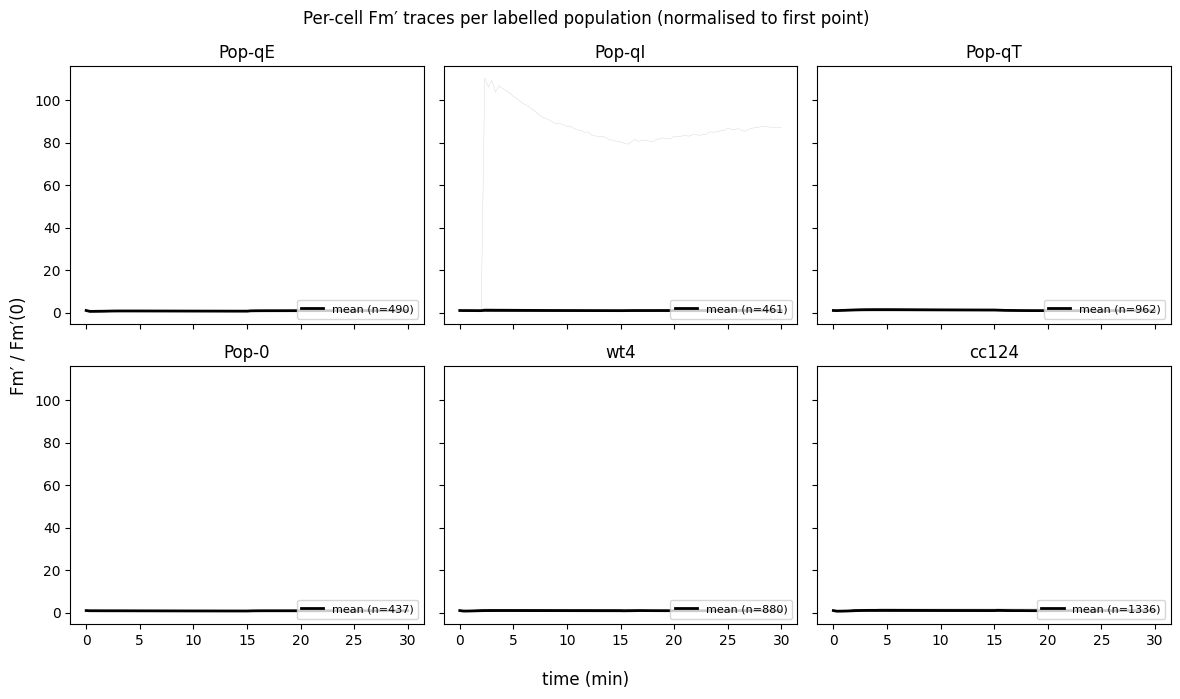

In [ ]:
state_list = ['Pop-qE', 'Pop-qI', 'Pop-qT', 'Pop-0', 'wt4', 'cc124']
t_min = np.linspace(0, 30, 91)  # minutes, authors' time axis

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for ax, st in zip(axes.ravel(), state_list):
    Y = df.loc[df["strain_state"] == st, value_cols].to_numpy(dtype=float)
    Y = Y / Y[:, 0:1]
    ax.plot(t_min, Y.T, color="grey", lw=0.3, alpha=0.35)
    ax.plot(t_min, Y.mean(axis=0), color="black", lw=2, label=f"mean (n={len(Y)})")
    ax.set_title(st)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Per-cell Fm′ traces per labelled population (normalised to first point)")
fig.supxlabel("time (min)")
fig.supylabel("Fm′ / Fm′(0)")
plt.tight_layout()
plt.show()


### 6. Load the authors' pretrained artifacts / 学習済み成果物の読み込み

`dico.pkl` is the authors' trained `MiniBatchDictionaryLearning` (k=10 atoms, `lars`
fit, sparse `lasso_lars` coding with ≤4 nonzero coefficients). The CSVs hold the LDA
standardization (`M_lda`, `S_lda`), the projection (`Tr`), the rotation onto the
population principal axes (`R`) and the origin shift (`origin`) saved by the authors'
`save_ouptut` — exactly the objects their scoring path consumes. We print shapes and
the estimator's key parameters as a load check.

/ dico.pklは著者が学習したスパース辞書（k=10）。CSV群はLDAの標準化・射影・主軸回転・原点移動のパラメータで、著者のスコアリング経路がそのまま使うものです。形状と主要パラメータを表示して確認します。

In [ ]:
art = ROOT / "output"
with open(art / "dico.pkl", "rb") as f:
    dict_learner = pickle.load(f)

M_lda = np.loadtxt(art / "dict_array_M_lda.csv")
S_lda = np.loadtxt(art / "dict_array_S_lda.csv")
Tr = np.loadtxt(art / "dict_array_Tr.csv")
R = np.loadtxt(art / "dict_array_R.csv")
origin = np.loadtxt(art / "dict_array_origin.csv")

print(type(dict_learner).__name__,
      "| n_components =", dict_learner.n_components,
      "| transform =", dict_learner.transform_algorithm)
print("M_lda", M_lda.shape, "| S_lda", S_lda.shape, "| Tr", Tr.shape,
      "| R", R.shape, "| origin", origin.shape)
assert dict_learner.n_components == 10 and Tr.shape == (10, 3) and R.shape == (3, 3)


MiniBatchDictionaryLearning | n_components = 10 | transform = lasso_lars
M_lda (10,) | S_lda (10,) | Tr (10, 3) | R (3, 3) | origin (3,)


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator MiniBatchDictionaryLearning from version 1.5.0 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


### 7. Score all labelled traces in the 3D NPQ space / 全トレースを3D NPQ空間へ投影

Following the authors' notebook: keep the six labelled `strain_state` populations with
`surface > 5` px (their selection cell), normalise each trace to a probability-like
profile (`x / row-sum`, their `normalize="proba"`), compute the sparse atom codes with
the loaded dictionary, then apply the authors' `transform_data` — standardize, project
(`Tr`), rotate onto the population principal axes (`R`), shift the origin, and flip the
first axis. Resulting columns follow the authors' axis order: **q̃T, q̃E, q̃I**.

/ 著者の選択条件（6母集団、surface>5px）とproba正規化を適用し、辞書でスパース符号化した後、著者のtransform_dataでq̃T/q̃E/q̃I座標へ変換します。

In [ ]:
sel = df["strain_state"].isin(state_list) & (df["surface"] > 5)
sub = df[sel].reset_index(drop=True)
X = sub[value_cols].to_numpy(dtype=float)
X = X / np.expand_dims(np.sum(X, axis=1), 1)  # authors' "proba" normalisation
print(f"selected {X.shape[0]} of {len(df)} traces")

def transform_data(pulses, M_lda, S_lda, Tr, R, origin):
    # verbatim from the authors' DL_LDA.ipynb (scoring path)
    XT = (pulses - M_lda) / S_lda
    XT = np.dot(XT, Tr)
    XT = np.dot(XT, R.T)
    XT = XT - origin
    XT[:, 0] = -XT[:, 0]
    return XT

codes = dict_learner.transform(X)  # sparse atom codes, shape (n, 10)
scores = transform_data(codes, M_lda, S_lda, Tr, R, origin)
print("scores:", scores.shape, "-> columns [q̃T, q̃E, q̃I] (authors' axis order)")


selected 4255 of 42127 traces


scores: (4255, 3) -> columns [q̃T, q̃E, q̃I] (authors' axis order)


### 8. Plausibility check 1: dictionary reconstruction error / 確認1：辞書再構成誤差

The paper reports reconstruction errors ≈2×10⁻⁴ for the training populations and
≈2.5×10⁻⁴ for unseen wt4 traces. As an independent load/scoring check we reconstruct
each normalised trace from its sparse codes (`codes @ dictionary components_`) and
report the per-trace mean squared error on the proba-normalized traces plus a relative
L2 error. The paper's exact error metric is not restated in the released code, so this
is an order-of-magnitude plausibility check: values well below ≈2×10⁻⁴ are consistent
with the paper's "threshold met" statement; a large error would indicate a broken load
or normalization.

/ 論文は学習母集団で再構成誤差≈2×10⁻⁴を報告しています。ここでは独立の確認として、proba正規化トレースをスパース符号から再構成し、トレースごとの平均二乗誤差と相対L2誤差を報告します。論文の指標の厳密な定義はコードに明記されていないため、桁の整合の確認です。

In [ ]:
recon = codes @ dict_learner.components_
sq_err = ((X - recon) ** 2).mean(axis=1)  # per-trace mean squared error (proba-normalised)
rel_err = np.linalg.norm(X - recon, axis=1) / np.linalg.norm(X, axis=1)
print(f"per-trace MSE : mean {sq_err.mean():.2e}, median {np.median(sq_err):.2e}, "
      f"95th pct {np.percentile(sq_err, 95):.2e}  (paper scale: <= 2e-4)")
print(f"relative L2   : mean {rel_err.mean():.2e}, median {np.median(rel_err):.2e}")
for st in ["Pop-0", "Pop-qE", "Pop-qI", "Pop-qT", "wt4", "cc124"]:
    m = (sub["strain_state"] == st).to_numpy()
    print(f"  {st:<8} MSE {sq_err[m].mean():.2e}   rel.L2 {rel_err[m].mean():.2e}")


per-trace MSE : mean 2.10e-08, median 1.07e-08, 95th pct 6.10e-08  (paper scale: <= 2e-4)
relative L2   : mean 1.08e-02, median 9.36e-03
  Pop-0    MSE 7.11e-09   rel.L2 6.86e-03
  Pop-qE   MSE 5.79e-08   rel.L2 1.79e-02
  Pop-qI   MSE 1.42e-08   rel.L2 5.93e-03
  Pop-qT   MSE 6.44e-09   rel.L2 6.74e-03
  wt4      MSE 2.48e-08   rel.L2 1.35e-02
  cc124    MSE 2.27e-08   rel.L2 1.26e-02


### 9. Plausibility check 2: populations separate along their dedicated axes / 確認2：母集団の軸ごとの分離

The axes were built from the population principal directions: axis q̃T ← Pop-qT cloud,
q̃E ← Pop-qE cloud, and q̃I ← their cross product. Under the authors' saved transform
(their `transform_data` flips only the first axis), Pop-qT and Pop-qE reach their
**maximum** mean on their dedicated axis, while Pop-qI occupies the **negative** end of
the q̃I axis — its dedicated extremum is the minimum. Each of these extremal separations
is what the paper's Fig. 2 shows. As an additional provenance check, the four training
populations (Pop-0, Pop-qE, Pop-qI, Pop-qT) total **2302 traces, exactly the count the
paper reports** before outlier removal.

/ 各軸は母集団の主方向から作られています。著者の保存済み変換では、Pop-qTとPop-qEは専用軸で最大、Pop-qIはq̃I軸の負側で分離します。また、学習用4母集団の合計は論文記載の2302トレースと一致します。

In [ ]:
axis_names = ["q̃T", "q̃E", "q̃I"]
tab = []
for st in ["Pop-0", "Pop-qE", "Pop-qI", "Pop-qT", "wt4", "cc124"]:
    m = (sub["strain_state"] == st).to_numpy()
    tab.append([st, int(m.sum()), *np.round(scores[m].mean(axis=0), 4)])
res = pd.DataFrame(tab, columns=["population", "n", *axis_names]).set_index("population")
display(res)

n_train = res.loc[["Pop-0", "Pop-qE", "Pop-qI", "Pop-qT"], "n"].sum()
print(f"training populations total: {n_train} traces (paper: 2302)")

expect = {"Pop-qT": ("q̃T", "max"), "Pop-qE": ("q̃E", "max"), "Pop-qI": ("q̃I", "min")}
for pop, (axis, direction) in expect.items():
    vals = res[axis]
    dedicated = vals.loc[pop]
    others = vals.drop(index=pop)
    ok = dedicated > others.max() if direction == "max" else dedicated < others.min()
    print(f"{pop}: mean {axis} = {dedicated:+.3f} -> dedicated-axis {direction}: "
          f"{'OK' if ok else 'UNEXPECTED'} "
          f"(other populations span {others.min():+.2f} ... {others.max():+.2f})")


,n,q̃T,q̃E,q̃I
population,,,,
Pop-0,433,0.4382,-0.2585,0.3388
Pop-qE,480,-0.8201,4.1557,1.3323
Pop-qI,453,0.3330,-0.3266,-1.8094
Pop-qT,936,6.9007,-0.0250,-1.6478
wt4,860,2.3896,2.7265,0.6537
cc124,1093,4.0809,2.1454,-0.0197


training populations total: 2302 traces (paper: 2302)
Pop-qT: mean q̃T = +6.901 -> dedicated-axis max: OK (other populations span -0.82 ... +4.08)
Pop-qE: mean q̃E = +4.156 -> dedicated-axis max: OK (other populations span -0.33 ... +2.73)
Pop-qI: mean q̃I = -1.809 -> dedicated-axis min: OK (other populations span -1.65 ... +1.33)


### 10. The 3D NPQ space, projected (analogous to paper Figs. 2 & 4) / 3D NPQ空間の射影図

Each dot is one cell; colors are the six labelled populations. This is the paper's core
picture: the reference populations occupy distinguishable regions of the q̃E–q̃T plane
(training populations Pop-qE/Pop-qI/Pop-qT along their dedicated axes), while the wild
types (`wt4`, `cc124`) spread across the space. *Analogous to* — not a pixel-level
reproduction of — the published figures.

/ 各点が1細胞、色は6母集団です。参照母集団がq̃E–q̃T平面の固有領域に分かれ、野生型が空間を広く占める、という論文の中心的な図の「類似図」です。

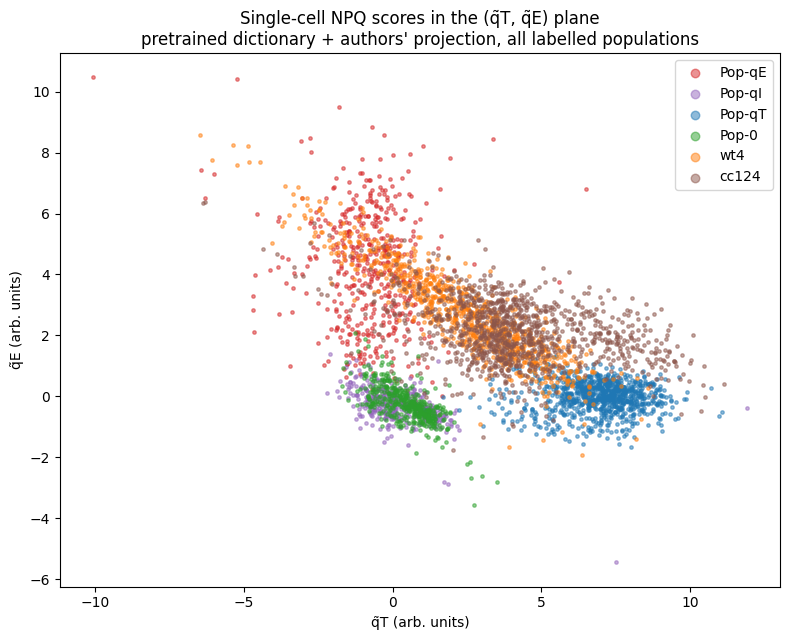

In [ ]:
colors = {"Pop-0": "tab:green", "Pop-qE": "tab:red", "Pop-qI": "tab:purple",
          "Pop-qT": "tab:blue", "wt4": "tab:orange", "cc124": "tab:brown"}
fig, ax = plt.subplots(figsize=(8, 6.5))
for st in state_list:
    m = (sub["strain_state"] == st).to_numpy()
    ax.scatter(scores[m, 0], scores[m, 1], s=6, alpha=0.5, color=colors[st], label=st)
ax.set_xlabel("q̃T (arb. units)")
ax.set_ylabel("q̃E (arb. units)")
ax.set_title("Single-cell NPQ scores in the (q̃T, q̃E) plane\n"
             "pretrained dictionary + authors' projection, all labelled populations")
ax.legend(markerscale=2.5)
plt.tight_layout()
plt.show()


### 11. Static 3D view of the full space / 3D空間の静的ビュー

A static 3-D rendering of the same scores (durable evidence; interactive widgets alone
are not). Expectations: Pop-qE extends along q̃E, Pop-qT along q̃T, Pop-qI lies at the
negative end of q̃I (the authors' saved sign convention), and Pop-0 clusters near the
origin.

/ 同じスコアの静的3D図です。Pop-qEはq̃E軸、Pop-qTはq̃T軸方向に伸び、Pop-qIは著者の符号規約の下でq̃I軸の負側、Pop-0は原点付近に集まります。

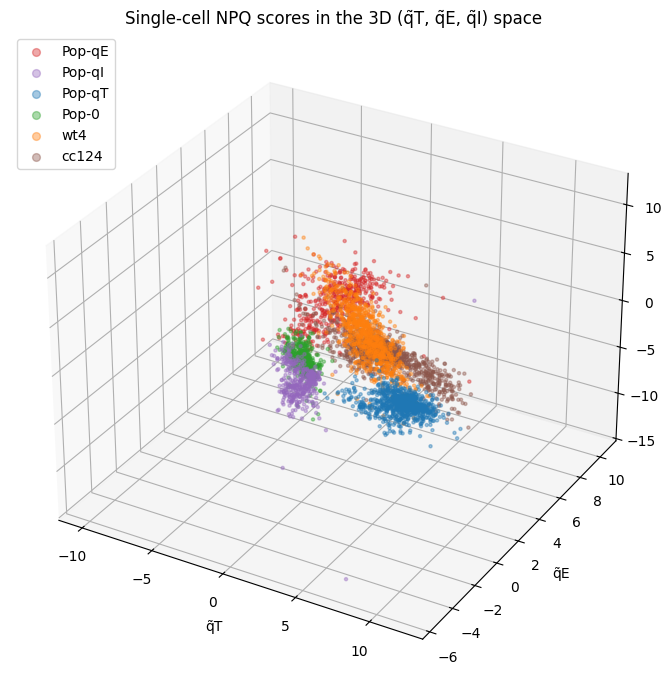

In [ ]:
fig = plt.figure(figsize=(8.5, 7))
ax = fig.add_subplot(projection="3d")
for st in state_list:
    m = (sub["strain_state"] == st).to_numpy()
    ax.scatter(scores[m, 0], scores[m, 1], scores[m, 2], s=5, alpha=0.4,
               color=colors[st], label=st)
ax.set_xlabel("q̃T")
ax.set_ylabel("q̃E")
ax.set_zlabel("q̃I")
ax.set_title("Single-cell NPQ scores in the 3D (q̃T, q̃E, q̃I) space")
ax.legend(markerscale=2.5, loc="upper left")
plt.tight_layout()
plt.show()


### 12. Wild types in the space (analogous to paper Fig. 4) / 野生型の投影図

The paper's biological result: in the WT `wt4a-`, single-cell q̃E and q̃T are strongly
(anti)correlated, while `cc124` shows the bulk trend without single-cell correlation.
We overlay the two wild types on the q̃T–q̃E plane and print the Pearson correlation of
q̃E vs q̃T within each strain — a minimal quantitative echo of Fig. 4(a)/(d).

/ 論文の生物学的結果：wt4では単細胞レベルでq̃Eとq̃Tに強い相関があり、cc124では集団レベルの傾向のみです。2つの野生型をq̃T–q̃E平面に重ね、各株内のq̃E–q̃Tピアソン相関を表示します（Fig. 4の定量的な最小エコー）。

wt4: Pearson corr(q̃E, q̃T) = -0.910 over 860 cells
cc124: Pearson corr(q̃E, q̃T) = -0.407 over 1093 cells


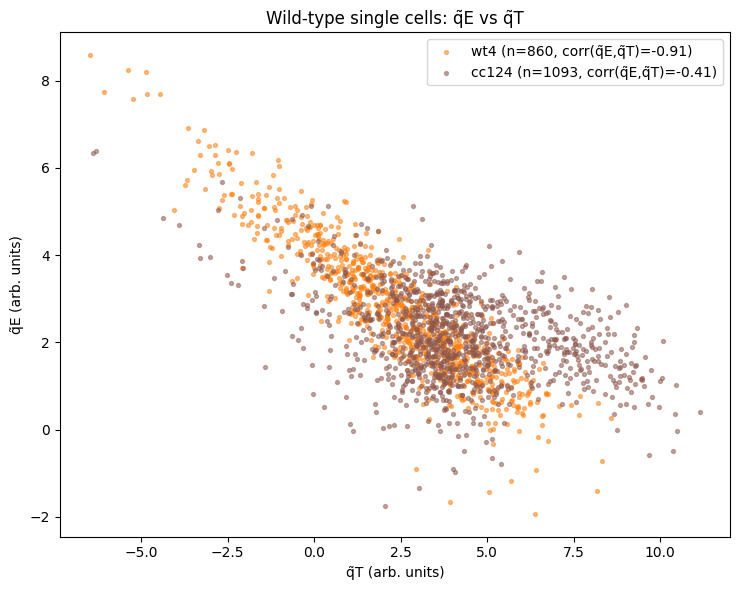

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for st in ["wt4", "cc124"]:
    m = (sub["strain_state"] == st).to_numpy()
    s = scores[m]
    r = np.corrcoef(s[:, 1], s[:, 0])[0, 1]
    ax.scatter(s[:, 0], s[:, 1], s=8, alpha=0.5, color=colors[st],
               label=f"{st} (n={m.sum()}, corr(q̃E,q̃T)={r:+.2f})")
    print(f"{st}: Pearson corr(q̃E, q̃T) = {r:+.3f} over {m.sum()} cells")
ax.set_xlabel("q̃T (arb. units)")
ax.set_ylabel("q̃E (arb. units)")
ax.set_title("Wild-type single cells: q̃E vs q̃T")
ax.legend()
plt.tight_layout()
plt.show()


### 13. Export the scores / スコアのエクスポート

We save every cell's q̃T/q̃E/q̃I score with its population label and a few key parameters
to `/content/npq_scores.csv` (Colab VM filesystem, downloadable via the file browser).

/ 全細胞のq̃T/q̃E/q̃Iスコアと母集団ラベル等を /content/npq_scores.csv に保存します（Colabのファイルブラウザからダウンロード可能）。

In [ ]:
out = sub[["run_id", "algae", "strain_state", "surface", "HL_time", "variant"]].copy()
out[["qT", "qE", "qI"]] = scores
out_path = "/content/npq_scores.csv"
out.to_csv(out_path, index=False)
print(f"wrote {len(out)} rows to {out_path}")
out.head()


wrote 4255 rows to /content/npq_scores.csv


,run_id,algae,strain_state,surface,HL_time,variant,qT,qE,qI
0,4,1,Pop-qT,15,15.0,NaN,6.900442,-0.010156,-4.607459
1,4,2,Pop-qT,19,15.0,NaN,7.343771,-1.166094,-3.108939
2,4,3,Pop-qT,52,15.0,NaN,3.861532,-1.084426,-1.424083
3,4,4,Pop-qT,44,15.0,NaN,5.415991,0.372123,-2.764009
4,4,5,Pop-qT,61,15.0,NaN,6.260934,-0.505351,-4.573949


## Interpretation & validation record / 解釈と検証記録

**What was executed** (this run, CPU): download of the pinned dataset + pretrained
artifacts with blob-SHA verification; loading of the authors' released dictionary and
projection; scoring of all six labelled populations; reconstruction-error and
axis-separation plausibility checks; the projection views above.

**Expected outcome** (verify against the printed outputs): the three training
populations each attain their maximum mean score on their dedicated axis; `wt4` and
`cc124` spread across the q̃E–q̃T plane with negative correlation, echoing the paper's
Fig. 2/4 structure. If the axis-separation check fails loudly, the released artifacts,
our normalization, or the axis order is wrong — treat results as invalid.

**Not done / not verified**: dictionary/LDA **retraining** (see the authors'
`DL_LDA.ipynb` cells 23–34: `MiniBatchDictionaryLearning` k=10, lars, α=1×10⁻⁶,
batch 64, seed 37, then 3-component LDA on atom codes); microscope build/acquisition
(paper Figs. 1, S1–S18); the D=0.005/D=0.01 outlier threshold discrepancy between
notebook and paper affects training only; no LICENSE file exists in the repository
(paper is CC BY 4.0) — reuse of the redistributed artifacts follows the published
paper's terms; figure↔`run_id` mapping is undocumented upstream.

**References**
- Paper: *New Phytologist* 250(4):2689–2705 (2026), DOI 10.1111/nph.71001; PMCID PMC13103431 (CC BY 4.0).
- Code & data: https://github.com/DreamRepo/NPQScore-data @ `4f0a787f327fd7d75c5a25a9d037dc937bc7e026`
  (`DL_LDA.ipynb`, `README.md`, `dataset.zip` blob `484cb57`, `output/` artifacts).
- AI-generated research-guidance lead used for provenance only: PhenoPaper investigation
  `p-dafd297cf548388708792ff89c206fda-20261118T210631Z-3826894` (not primary evidence).